# Val → Train Closest Molecule Analysis

For each val-set `(spectrum, mol)` pair:
1. Find the closest training-set molecule that **shares the same molecular formula** (by ECFP Tanimoto).
2. Match that train mol's spectrum using the same adduct + instrument type and the closest CE.
3. Compute cosine similarity between the val and train spectra.

Use this to understand how structurally similar the closest same-formula train analogue is, and whether spectral similarity tracks structural similarity.

## Configuration

In [18]:
# ── Paths ─────────────────────────────────────────────────────────────────────
SPEC_FP   = "../../data/proc/nist20/spec_df.pkl"
MOL_FP    = "../../data/proc/nist20/mol_df.pkl"
SPLIT_DP  = "../../data/split/nist20_inchikey"
OUTPUT_FP = None

# ── Filters ───────────────────────────────────────────────────────────────────
ADDUCT_FILTER   = []    # e.g. ["[M+H]+"]   ; empty = all
INST_FILTER     = []    # e.g. ["FT"]        ; empty = all
MAX_VAL_SPECS   = 2000  # 0 = no cap

# ── Fingerprint ───────────────────────────────────────────────────────────────
MORGAN_RADIUS = 3
MORGAN_NBITS  = 2048

# ── Plotting ──────────────────────────────────────────────────────────────────
FIG_DPI    = 120
FIG_STYLE  = "ggplot"

## Imports

In [19]:
from __future__ import annotations

import logging
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
logger = logging.getLogger(__name__)

plt.style.use(FIG_STYLE)
%matplotlib inline

## Helper Functions

In [20]:
# ── Fingerprint helpers ────────────────────────────────────────────────────────

def smiles_to_ecfp(smiles: str, radius: int = 3, nbits: int = 2048) -> np.ndarray | None:
    """Convert SMILES to ECFP bit-vector as a numpy array. Returns None if invalid."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=nbits)
    arr = np.zeros(nbits, dtype=np.uint8)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr


def tanimoto_matrix(query: np.ndarray, db: np.ndarray) -> np.ndarray:
    """Tanimoto similarity between a single query (1-D) and a DB matrix (N x bits)."""
    inter = db @ query
    q_sum = query.sum()
    db_sums = db.sum(axis=1)
    union = q_sum + db_sums - inter
    return np.where(union > 0, inter / union, 0.0).astype(np.float32)


# ── Spectrum cosine similarity ─────────────────────────────────────────────────

def peaks_to_array(peaks, mz_max: float = 1500.0, bin_res: float = 0.1) -> np.ndarray:
    """Convert list of (mz, intensity) pairs to a normalised binned array."""
    n_bins = int(round(mz_max / bin_res))
    arr = np.zeros(n_bins, dtype=np.float32)
    if peaks is None:
        return arr
    for mz, intensity in peaks:
        idx = int(round(mz / bin_res))
        if 0 <= idx < n_bins:
            arr[idx] += intensity
    norm = np.linalg.norm(arr)
    if norm > 0:
        arr /= norm
    return arr


def cosine_sim(peaks_a, peaks_b, mz_max: float = 1500.0, bin_res: float = 0.1) -> float:
    """Cosine similarity between two spectra given as lists of (mz, intensity) pairs."""
    a = peaks_to_array(peaks_a, mz_max, bin_res)
    b = peaks_to_array(peaks_b, mz_max, bin_res)
    return float(np.dot(a, b))


# ── CE extraction ─────────────────────────────────────────────────────────────

def get_ce(row: pd.Series) -> float | None:
    """Prefer nce, fall back to ace. Return None if neither is available."""
    for col in ("nce", "ace"):
        if col in row.index:
            v = row[col]
            if v is not None and not (isinstance(v, float) and np.isnan(v)):
                return float(v)
    return None

## 1. Load Data

In [21]:
logger.info("Loading spec_df from %s", SPEC_FP)
spec_df: pd.DataFrame = pd.read_pickle(SPEC_FP)
logger.info("Loading mol_df from %s", MOL_FP)
mol_df: pd.DataFrame = pd.read_pickle(MOL_FP)

print(f"spec_df: {spec_df.shape}   mol_df: {mol_df.shape}")
spec_df.head(2)

2026-04-16 14:57:15,851 INFO Loading spec_df from ../../data/proc/nist20/spec_df.pkl
2026-04-16 14:59:51,607 INFO Loading mol_df from ../../data/proc/nist20/mol_df.pkl


spec_df: (1148072, 22)   mol_df: (35025, 14)


,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,nce,prec_mz,peaks,ri,group_id,ace_extra_1,nce_extra_1,ace_extra_2,nce_extra_2,ce_type
0,0,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035166,N2,...,NaN,1467.0061,"[(45.96, 46.35), (597.48, 51.85), (598.5, 41.3...",NaN,0,NaN,NaN,NaN,NaN,single
1,1,10998,[M+NH4]+,QTOF,CID,MS2,P,nist20_hr,1035167,N2,...,NaN,1467.0061,"[(597.5, 50.95), (599.5, 683.32), (1449.98, 99...",NaN,0,NaN,NaN,NaN,NaN,single


## 2. Load Splits

In [22]:
def load_split(name: str) -> pd.DataFrame:
    fp = os.path.join(SPLIT_DP, f"{name}_ids.csv")
    if not os.path.isfile(fp):
        raise FileNotFoundError(f"Split file not found: {fp}")
    return pd.read_csv(fp)

train_split = load_split("train")
val_split   = load_split("val")

train_spec_ids = set(train_split["spec_id"].unique())
train_mol_ids  = set(train_split["mol_id"].unique())
val_spec_ids   = set(val_split["spec_id"].unique())
val_mol_ids    = set(val_split["mol_id"].unique())

print(
    f"Train: {len(train_spec_ids):,} spectra, {len(train_mol_ids):,} mols  "
    f"Val: {len(val_spec_ids):,} spectra, {len(val_mol_ids):,} mols"
)

Train: 157,678 spectra, 12,668 mols  Val: 52,020 spectra, 4,222 mols


## 3. Build Val Spectra Table

In [23]:
val_spec_df = spec_df[spec_df["spec_id"].isin(val_spec_ids)].copy()

if ADDUCT_FILTER:
    val_spec_df = val_spec_df[val_spec_df["prec_type"].isin(ADDUCT_FILTER)]
    print(f"Val spectra after adduct filter: {len(val_spec_df)}")

if INST_FILTER:
    val_spec_df = val_spec_df[val_spec_df["inst_type"].isin(INST_FILTER)]
    print(f"Val spectra after inst filter: {len(val_spec_df)}")

if MAX_VAL_SPECS and MAX_VAL_SPECS > 0:
    val_spec_df = val_spec_df.sample(n=min(MAX_VAL_SPECS, len(val_spec_df)), random_state=42)

print(f"Processing {len(val_spec_df):,} val spectra")

Processing 2,000 val spectra


## 4. Build Training Molecule Index (ECFP)

In [24]:
mol_df = mol_df.set_index("mol_id")

train_mol_df = mol_df[mol_df.index.isin(train_mol_ids)].copy()
logger.info("Computing ECFP for %d training molecules …", len(train_mol_df))

fp_list = [smiles_to_ecfp(s, MORGAN_RADIUS, MORGAN_NBITS) for s in train_mol_df["smiles"]]
train_mol_df["ecfp"] = fp_list
train_mol_df = train_mol_df[train_mol_df["ecfp"].notna()].copy()
print(f"Train mols with valid ECFP: {len(train_mol_df):,}")

# Group by formula for fast same-formula lookup
train_by_formula: dict[str, pd.DataFrame] = {f: g for f, g in train_mol_df.groupby("formula")}

# Index train spectra by mol_id
train_spec_df = spec_df[spec_df["spec_id"].isin(train_spec_ids)]
train_specs_by_mol: dict[str, pd.DataFrame] = {mid: g for mid, g in train_spec_df.groupby("mol_id")}

2026-04-16 14:59:55,645 INFO Computing ECFP for 12668 training molecules …


Train mols with valid ECFP: 12,668


## 5. Main Loop: Match Val → Train

In [25]:
mol_match_cache: dict[str, tuple[str, str, float] | None] = {}
rows = []
n_no_formula_match = 0
n_no_spec_match = 0

for _, v_spec in val_spec_df.iterrows():
    val_mol_id: str = v_spec["mol_id"]
    val_spec_id: str = v_spec["spec_id"]
    adduct: str = v_spec["prec_type"]
    inst: str = v_spec["inst_type"]
    v_ce = get_ce(v_spec)

    if val_mol_id not in mol_df.index:
        continue
    val_mol_row = mol_df.loc[val_mol_id]
    formula: str = val_mol_row["formula"]
    val_smiles: str = val_mol_row["smiles"]

    # --- closest train mol (cached per val mol_id) -------------------------
    if val_mol_id not in mol_match_cache:
        val_fp = smiles_to_ecfp(val_smiles, MORGAN_RADIUS, MORGAN_NBITS)
        if val_fp is None or formula not in train_by_formula:
            mol_match_cache[val_mol_id] = None
        else:
            cand = train_by_formula[formula]
            cand_fps = np.stack(cand["ecfp"].tolist(), axis=0)
            sims = tanimoto_matrix(val_fp, cand_fps)
            best_idx = int(np.argmax(sims))
            mol_match_cache[val_mol_id] = (
                cand.index[best_idx],
                cand.iloc[best_idx]["smiles"],
                float(sims[best_idx]),
            )

    match = mol_match_cache[val_mol_id]
    if match is None:
        n_no_formula_match += 1
        continue

    best_train_mol_id, best_train_smiles, tanimoto = match

    # --- find train spectrum: same adduct + inst, closest CE ---------------
    train_specs = train_specs_by_mol.get(best_train_mol_id)
    _base_row = dict(
        val_spec_id=val_spec_id, val_mol_id=val_mol_id, val_smiles=val_smiles,
        formula=formula, adduct=adduct, inst_type=inst, val_ce=v_ce,
        train_mol_id=best_train_mol_id, train_smiles=best_train_smiles, tanimoto=tanimoto,
        train_spec_id=None, train_ce=None, ce_diff=None, cosine_sim=None,
    )

    if train_specs is None or len(train_specs) == 0:
        n_no_spec_match += 1
        rows.append(_base_row)
        continue

    t_subs = train_specs[
        (train_specs["prec_type"] == adduct) & (train_specs["inst_type"] == inst)
    ]
    if len(t_subs) == 0:
        n_no_spec_match += 1
        rows.append(_base_row)
        continue

    t_ces = [get_ce(r) for _, r in t_subs.iterrows()]
    if v_ce is not None and any(tc is not None for tc in t_ces):
        diffs = [abs(v_ce - tc) if tc is not None else float("inf") for tc in t_ces]
        best_t_idx = int(np.argmin(diffs))
        ce_diff: float | None = diffs[best_t_idx] if diffs[best_t_idx] != float("inf") else None
    else:
        best_t_idx = 0
        ce_diff = None

    t_row = t_subs.iloc[best_t_idx]
    t_ce  = t_ces[best_t_idx]
    cos   = cosine_sim(v_spec["peaks"], t_row["peaks"])

    rows.append({**_base_row,
        "train_spec_id": t_row["spec_id"],
        "train_ce": t_ce,
        "ce_diff": ce_diff,
        "cosine_sim": cos,
    })

result_df = pd.DataFrame(rows)
print(f"Result rows: {len(result_df):,}")
result_df.head(3)

Result rows: 1,062


,val_spec_id,val_mol_id,val_smiles,formula,adduct,inst_type,val_ce,train_mol_id,train_smiles,tanimoto,train_spec_id,train_ce,ce_diff,cosine_sim
0,78440,34985,c1cncc(C2CCCN2)c1,C9H12N2,[M+H]+,FT,180.0,34889,c1ccc2c(c1)CNCCN2,0.137931,726371,160.0,20.0,0.631317
1,991231,32816,O=[N+]([O-])c1cccc(S(=O)(=O)NCCO)c1,C8H10N2O5S,[M+H]+,FT,100.0,15110,CN(C)S(=O)(=O)Oc1ccc([N+](=O)[O-])cc1,0.203125,825642,65.0,35.0,0.028361
2,117802,15446,CN1CCCC1C(=O)O,C6H11NO2,[M+H]+,FT,20.0,29461,O=C(O)C1CCCCN1,0.243243,64319,20.0,0.0,0.999861


## 6. Save Results (optional)

In [26]:
if OUTPUT_FP:
    out_fp = Path(OUTPUT_FP)
    out_fp.parent.mkdir(parents=True, exist_ok=True)
    result_df.to_pickle(str(out_fp))
    print(f"Saved to {out_fp}")

## 7. Coverage Summary

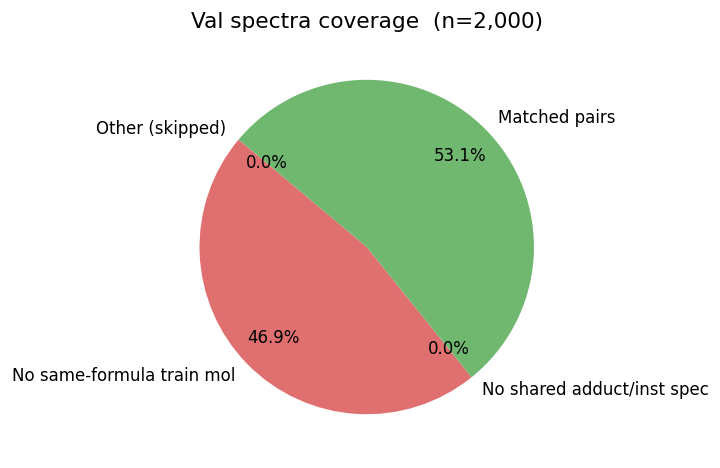

Val spectra processed       : 2,000
No same-formula train mol   : 938  (46.9%)
No shared adduct/inst specs : 0  (0.0%)
Matched pairs               : 1,062  (53.1%)


In [27]:
matched = result_df[result_df["cosine_sim"].notna()].copy() if len(result_df) > 0 else pd.DataFrame()
n_total   = len(val_spec_df)
n_matched = len(matched)

labels = ["No same-formula train mol", "No shared adduct/inst spec", "Matched pairs", "Other (skipped)"]
counts = [
    n_no_formula_match,
    n_no_spec_match,
    n_matched,
    n_total - n_no_formula_match - n_no_spec_match - n_matched,
]
counts = [max(c, 0) for c in counts]  # guard

fig, ax = plt.subplots(figsize=(7, 4), dpi=FIG_DPI)
colors = ["#e07070", "#e0a870", "#70b870", "#a0a0a0"]
wedges, texts, autotexts = ax.pie(
    counts, labels=labels, colors=colors, autopct="%1.1f%%",
    startangle=140, pctdistance=0.78,
)
ax.set_title(f"Val spectra coverage  (n={n_total:,})", fontsize=13)
plt.tight_layout()
plt.show()

print(f"Val spectra processed       : {n_total:,}")
print(f"No same-formula train mol   : {n_no_formula_match:,}  ({100*n_no_formula_match/n_total:.1f}%)")
print(f"No shared adduct/inst specs : {n_no_spec_match:,}  ({100*n_no_spec_match/n_total:.1f}%)")
print(f"Matched pairs               : {n_matched:,}  ({100*n_matched/n_total:.1f}%)")

## 8. Tanimoto Similarity Distribution

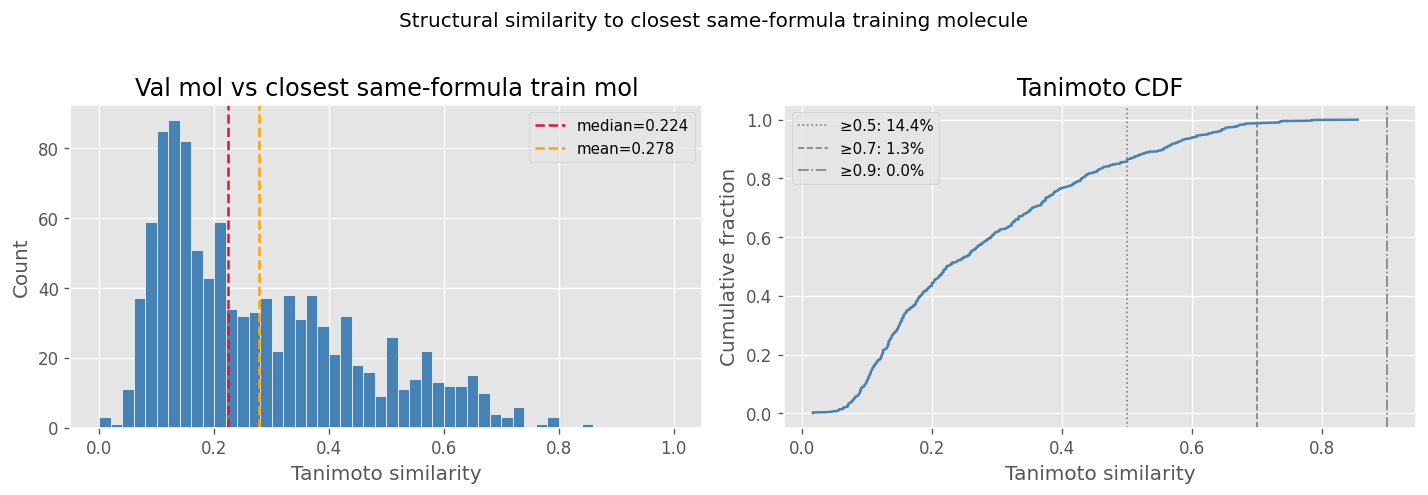

n=1,062  mean=0.2785  median=0.2238  p10=0.0984  p90=0.5556


In [28]:
tan_valid = result_df["tanimoto"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=FIG_DPI)

# Histogram
ax = axes[0]
ax.hist(tan_valid, bins=50, range=(0, 1), color="steelblue", edgecolor="white", linewidth=0.4)
ax.axvline(tan_valid.median(), color="crimson", linestyle="--", linewidth=1.5,
           label=f"median={tan_valid.median():.3f}")
ax.axvline(tan_valid.mean(), color="orange", linestyle="--", linewidth=1.5,
           label=f"mean={tan_valid.mean():.3f}")
ax.set_xlabel("Tanimoto similarity")
ax.set_ylabel("Count")
ax.set_title("Val mol vs closest same-formula train mol")
ax.legend(fontsize=9)

# CDF
ax = axes[1]
sorted_tan = np.sort(tan_valid)
cdf = np.arange(1, len(sorted_tan) + 1) / len(sorted_tan)
ax.plot(sorted_tan, cdf, color="steelblue", linewidth=1.5)
for thr, ls in [(0.5, ":"), (0.7, "--"), (0.9, "-.")]:
    frac = (sorted_tan >= thr).mean()
    ax.axvline(thr, color="gray", linestyle=ls, linewidth=1, label=f"≥{thr}: {frac:.1%}")
ax.set_xlabel("Tanimoto similarity")
ax.set_ylabel("Cumulative fraction")
ax.set_title("Tanimoto CDF")
ax.legend(fontsize=9)

plt.suptitle("Structural similarity to closest same-formula training molecule", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

print(f"n={len(tan_valid):,}  mean={tan_valid.mean():.4f}  median={tan_valid.median():.4f}"
      f"  p10={tan_valid.quantile(0.1):.4f}  p90={tan_valid.quantile(0.9):.4f}")

## 9. Cosine Similarity Distribution

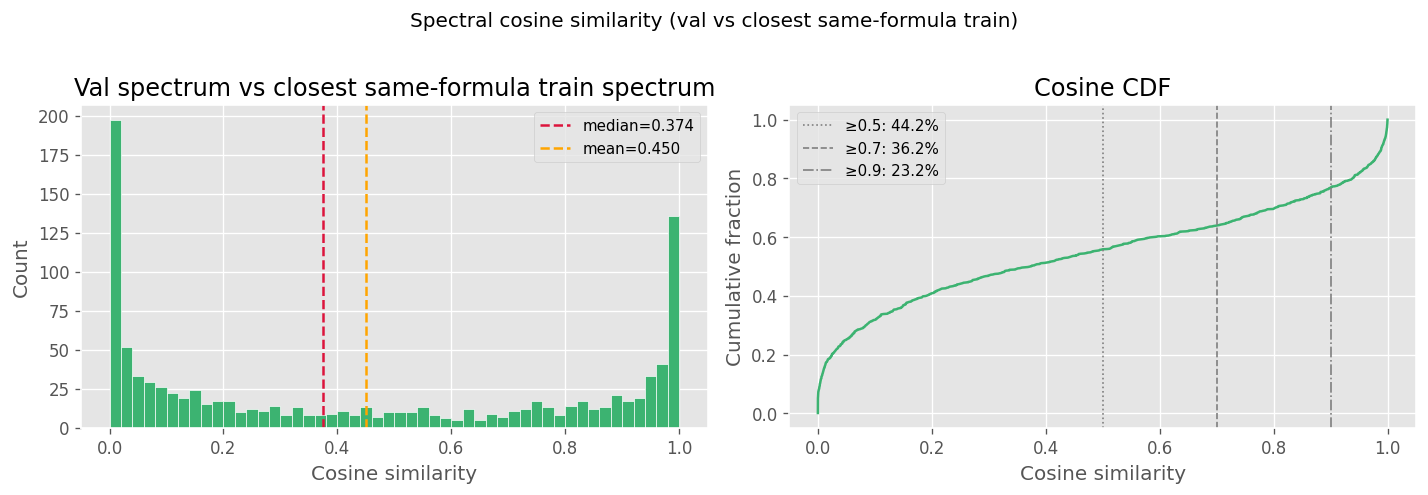

n=1,062  mean=0.4499  median=0.3742  p10=0.0038  p90=0.9888


In [29]:
cos_valid = matched["cosine_sim"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=FIG_DPI)

# Histogram
ax = axes[0]
ax.hist(cos_valid, bins=50, range=(0, 1), color="mediumseagreen", edgecolor="white", linewidth=0.4)
ax.axvline(cos_valid.median(), color="crimson", linestyle="--", linewidth=1.5,
           label=f"median={cos_valid.median():.3f}")
ax.axvline(cos_valid.mean(), color="orange", linestyle="--", linewidth=1.5,
           label=f"mean={cos_valid.mean():.3f}")
ax.set_xlabel("Cosine similarity")
ax.set_ylabel("Count")
ax.set_title("Val spectrum vs closest same-formula train spectrum")
ax.legend(fontsize=9)

# CDF
ax = axes[1]
sorted_cos = np.sort(cos_valid)
cdf = np.arange(1, len(sorted_cos) + 1) / len(sorted_cos)
ax.plot(sorted_cos, cdf, color="mediumseagreen", linewidth=1.5)
for thr, ls in [(0.5, ":"), (0.7, "--"), (0.9, "-.")]:
    frac = (sorted_cos >= thr).mean()
    ax.axvline(thr, color="gray", linestyle=ls, linewidth=1, label=f"≥{thr}: {frac:.1%}")
ax.set_xlabel("Cosine similarity")
ax.set_ylabel("Cumulative fraction")
ax.set_title("Cosine CDF")
ax.legend(fontsize=9)

plt.suptitle("Spectral cosine similarity (val vs closest same-formula train)", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

print(f"n={len(cos_valid):,}  mean={cos_valid.mean():.4f}  median={cos_valid.median():.4f}"
      f"  p10={cos_valid.quantile(0.1):.4f}  p90={cos_valid.quantile(0.9):.4f}")

## 10. Tanimoto vs Cosine Similarity to the Closest Mol in Training Set

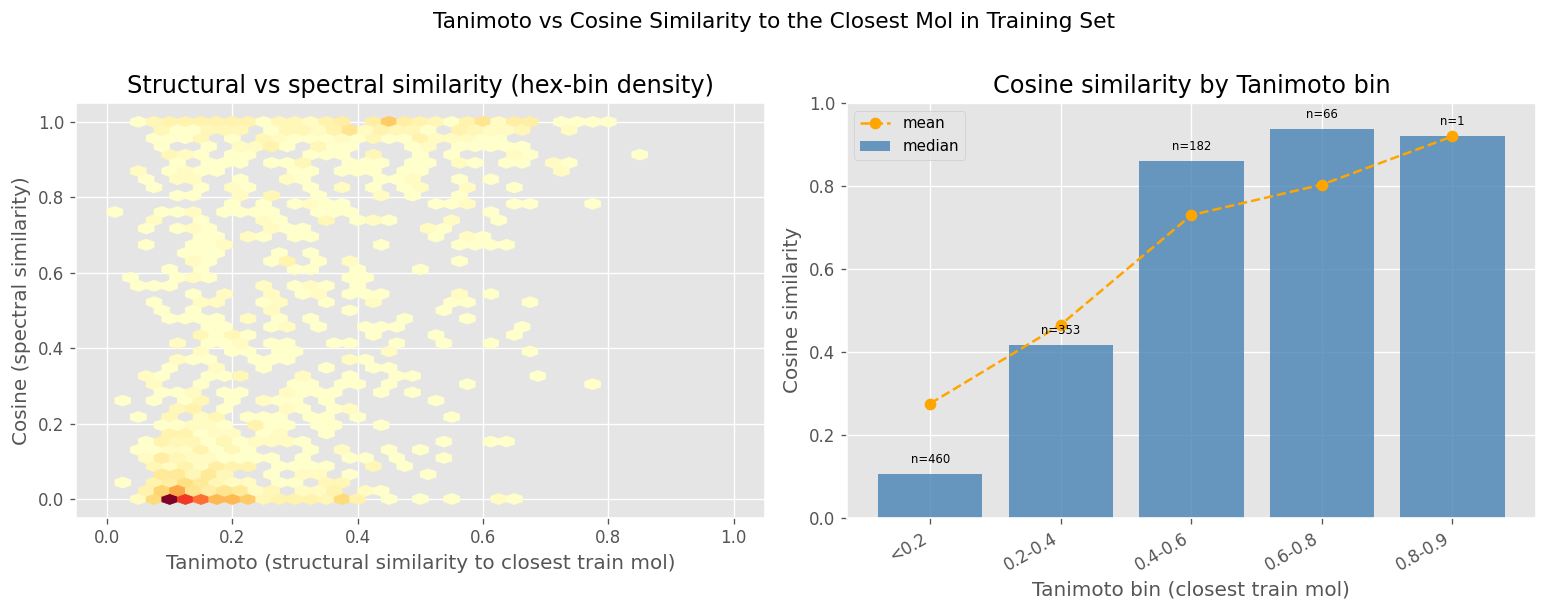

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=FIG_DPI)

# Scatter with density
ax = axes[0]
ax.hexbin(
    matched["tanimoto"], matched["cosine_sim"],
    gridsize=40, cmap="YlOrRd", mincnt=1, extent=(0, 1, 0, 1),
)
ax.set_xlabel("Tanimoto (structural similarity to closest train mol)")
ax.set_ylabel("Cosine (spectral similarity)")
ax.set_title("Structural vs spectral similarity (hex-bin density)")

# Binned median
ax = axes[1]
tan_bins   = [0.0, 0.2, 0.4, 0.6, 0.8, 0.9, 1.0, float("inf")]
tan_labels = ["<0.2", "0.2-0.4", "0.4-0.6", "0.6-0.8", "0.8-0.9", "0.9-1.0", "=1.0"]
matched_copy = matched.copy()
matched_copy["tan_bin"] = pd.cut(
    matched_copy["tanimoto"], bins=tan_bins, labels=tan_labels, right=False
)
bin_stats = (
    matched_copy.groupby("tan_bin", observed=True)["cosine_sim"]
    .agg(["median", "mean", "count"])
    .reset_index()
)
x = range(len(bin_stats))
ax.bar(x, bin_stats["median"], color="steelblue", alpha=0.8, label="median")
ax.plot(x, bin_stats["mean"], "o--", color="orange", linewidth=1.5, label="mean")
ax.set_xticks(list(x))
ax.set_xticklabels(bin_stats["tan_bin"].tolist(), rotation=30, ha="right")
ax.set_xlabel("Tanimoto bin (closest train mol)")
ax.set_ylabel("Cosine similarity")
ax.set_title("Cosine similarity by Tanimoto bin")
ax.set_ylim(0, 1)
for xi, (_, row) in zip(x, bin_stats.iterrows()):
    ax.text(xi, row["median"] + 0.02, f"n={int(row['count'])}",
            ha="center", va="bottom", fontsize=7)
ax.legend(fontsize=9)

plt.suptitle("Tanimoto vs Cosine Similarity to the Closest Mol in Training Set", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 11. Cosine Similarity by Adduct

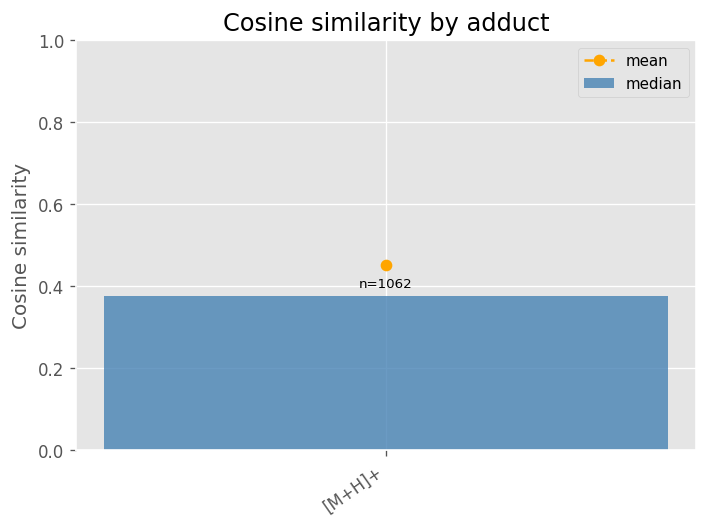

,adduct,median,mean,count
0,[M+H]+,0.3742,0.4499,1062


In [31]:
if "adduct" in matched.columns and matched["adduct"].nunique() > 0:
    adduct_stats = (
        matched.groupby("adduct")["cosine_sim"]
        .agg(["median", "mean", "count"])
        .sort_values("median", ascending=False)
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(max(6, len(adduct_stats) * 0.9), 4.5), dpi=FIG_DPI)
    x = range(len(adduct_stats))
    bars = ax.bar(x, adduct_stats["median"], color="steelblue", alpha=0.8, label="median")
    ax.plot(x, adduct_stats["mean"], "o--", color="orange", linewidth=1.5, label="mean")
    ax.set_xticks(list(x))
    ax.set_xticklabels(adduct_stats["adduct"].tolist(), rotation=35, ha="right")
    ax.set_ylabel("Cosine similarity")
    ax.set_title("Cosine similarity by adduct")
    ax.set_ylim(0, 1)
    for xi, (_, row) in zip(x, adduct_stats.iterrows()):
        ax.text(xi, row["median"] + 0.015, f"n={int(row['count'])}",
                ha="center", va="bottom", fontsize=8)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

    display(adduct_stats.round(4))
else:
    print("No adduct column or single adduct — skipping.")

## 12. Cosine Similarity by Instrument Type

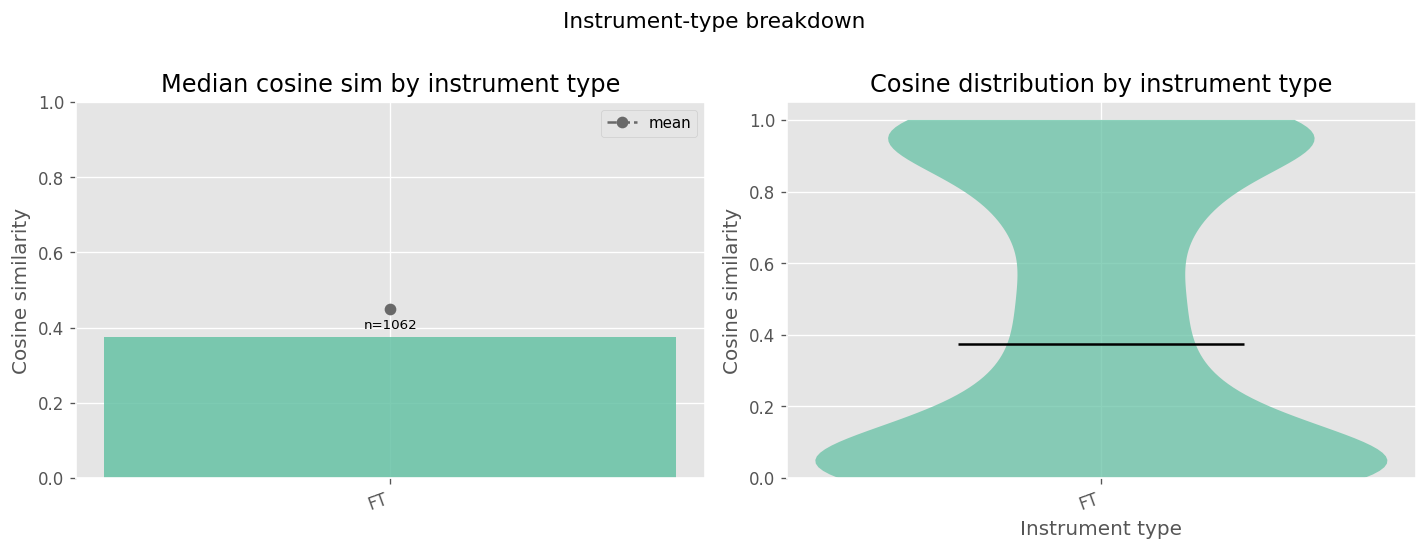

,inst_type,median,mean,count
0,FT,0.3742,0.4499,1062


In [32]:
if "inst_type" in matched.columns and matched["inst_type"].nunique() > 0:
    inst_stats = (
        matched.groupby("inst_type")["cosine_sim"]
        .agg(["median", "mean", "count"])
        .sort_values("median", ascending=False)
        .reset_index()
    )

    inst_order = inst_stats["inst_type"].tolist()
    n_inst = len(inst_order)
    # Use matplotlib's tab10 colormap as a Set2-style palette
    palette = [plt.cm.Set2(i / max(n_inst - 1, 1)) for i in range(n_inst)]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=FIG_DPI)

    # Bar chart
    ax = axes[0]
    x = range(n_inst)
    ax.bar(x, inst_stats["median"], color=palette, alpha=0.85)
    ax.plot(x, inst_stats["mean"], "o--", color="dimgray", linewidth=1.5, label="mean")
    ax.set_xticks(list(x))
    ax.set_xticklabels(inst_order, rotation=20, ha="right")
    ax.set_ylabel("Cosine similarity")
    ax.set_title("Median cosine sim by instrument type")
    ax.set_ylim(0, 1)
    for xi, (_, row) in zip(x, inst_stats.iterrows()):
        ax.text(xi, row["median"] + 0.015, f"n={int(row['count'])}",
                ha="center", va="bottom", fontsize=8)
    ax.legend(fontsize=9)

    # Violin (pure matplotlib)
    ax = axes[1]
    data_by_inst = [
        matched[matched["inst_type"] == inst]["cosine_sim"].dropna().values
        for inst in inst_order
    ]
    parts = ax.violinplot(data_by_inst, positions=list(x), showmedians=True, showextrema=False)
    for body, color in zip(parts["bodies"], palette):
        body.set_facecolor(color)
        body.set_alpha(0.75)
    parts["cmedians"].set_color("black")
    parts["cmedians"].set_linewidth(1.5)
    ax.set_xticks(list(x))
    ax.set_xticklabels(inst_order, rotation=20, ha="right")
    ax.set_xlabel("Instrument type")
    ax.set_ylabel("Cosine similarity")
    ax.set_title("Cosine distribution by instrument type")
    ax.set_ylim(0, 1.05)

    plt.suptitle("Instrument-type breakdown", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()

    display(inst_stats.round(4))
else:
    print("No inst_type column or single instrument type — skipping.")

## 13. CE Difference Distribution

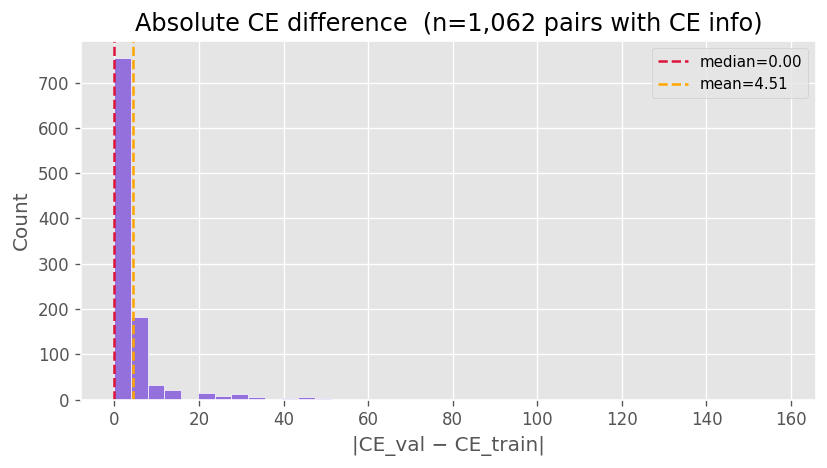

mean=4.509  median=0.000  p90=10.000  max=158.000


In [33]:
ce_diff = matched["ce_diff"].dropna()
if len(ce_diff) > 0:
    fig, ax = plt.subplots(figsize=(7, 4), dpi=FIG_DPI)
    ax.hist(ce_diff, bins=40, color="mediumpurple", edgecolor="white", linewidth=0.4)
    ax.axvline(ce_diff.median(), color="crimson", linestyle="--", linewidth=1.5,
               label=f"median={ce_diff.median():.2f}")
    ax.axvline(ce_diff.mean(), color="orange", linestyle="--", linewidth=1.5,
               label=f"mean={ce_diff.mean():.2f}")
    ax.set_xlabel("|CE_val − CE_train|")
    ax.set_ylabel("Count")
    ax.set_title(f"Absolute CE difference  (n={len(ce_diff):,} pairs with CE info)")
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

    print(f"mean={ce_diff.mean():.3f}  median={ce_diff.median():.3f}"
          f"  p90={ce_diff.quantile(0.9):.3f}  max={ce_diff.max():.3f}")
else:
    print("No CE info available in matched pairs.")

## 14. Tanimoto = 1.0 Cases (Identical Molecules?)

In [34]:
exact_matches = matched[matched["tanimoto"] >= 0.9999]
non_exact     = matched[matched["tanimoto"]  < 0.9999]

print(f"Tanimoto = 1.0 (fingerprint-identical): {len(exact_matches):,}  "
      f"({100*len(exact_matches)/len(matched):.1f}% of matched pairs)")
print(f"Tanimoto < 1.0 (different mol, same formula): {len(non_exact):,}")

if len(exact_matches) > 0 and len(non_exact) > 0:
    fig, ax = plt.subplots(figsize=(7, 4), dpi=FIG_DPI)
    ax.hist(exact_matches["cosine_sim"].dropna(), bins=30, range=(0, 1),
            alpha=0.6, color="steelblue", label=f"Tan=1.0  (n={len(exact_matches):,})")
    ax.hist(non_exact["cosine_sim"].dropna(), bins=30, range=(0, 1),
            alpha=0.6, color="tomato",    label=f"Tan<1.0  (n={len(non_exact):,})")
    ax.set_xlabel("Cosine similarity")
    ax.set_ylabel("Count")
    ax.set_title("Cosine: identical vs non-identical molecules (same formula)")
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

Tanimoto = 1.0 (fingerprint-identical): 0  (0.0% of matched pairs)
Tanimoto < 1.0 (different mol, same formula): 1,062
